In [ ]:
# save as make_ipr_vocab.py
import csv

entry_list = "InterPro/entry.list"
out_tsv = "InterPro/ipr_domain_entry.tsv"

domain_rows = []
with open(entry_list, "r") as f:
    # entry.list is typically tab-separated
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.split("\t")
        # Common formats:
        # IPRxxxxxx  <type>  <name> ...
        ipr = parts[0]
        # Find a field that looks like a type/category
        # We'll scan for known category keywords.
        type_field = parts[1]
        if type_field == "Domain":
            name = parts[2] if len(parts) > 2 else ""
            domain_rows.append((ipr, name))

# Assign integer IDs (reserve 0 for NONE)
domain_rows.sort(key=lambda x: x[0])
with open(out_tsv, "w", newline="") as fo:
    w = csv.writer(fo, delimiter="\t")
    w.writerow(["ipr", "name", "idx"])
    for idx, (ipr, name) in enumerate(domain_rows, start=1):
        w.writerow([ipr, name, idx])

print(f"Wrote {len(domain_rows)} domain labels to {out_tsv}")


In [ ]:
# save as build_uniref50_sqlite.py
import gzip
import sqlite3

FASTA = "uniref50/uniref50.fasta.gz"
DB = "uniref50/uniref50.sqlite"
LIMIT = None  # set e.g. 200000 for a pilot run

con = sqlite3.connect(DB)
cur = con.cursor()

cur.execute("PRAGMA journal_mode=WAL;")
cur.execute("PRAGMA synchronous=OFF;")
cur.execute("PRAGMA temp_store=MEMORY;")

cur.execute("""
CREATE TABLE IF NOT EXISTS protein (
  rep_id TEXT PRIMARY KEY,
  seq TEXT NOT NULL,
  len INTEGER NOT NULL
);
""")
con.commit()

def parse_rep_id(header: str) -> str:
    # Header example:
    # >UniRef50_UPI002E2621C6 uncharacterized ... RepID=UPI002E2621C6
    # We take token after >UniRef50_
    first = header.split()[0]
    assert first.startswith(">UniRef50_")
    return first[len(">UniRef50_"):]

batch = []
n = 0
with gzip.open(FASTA, "rt") as f:
    rep_id = None
    seq_chunks = []
    for line in f:
        line = line.rstrip("\n")
        if line.startswith(">"):
            if rep_id is not None:
                seq = "".join(seq_chunks)
                batch.append((rep_id, seq, len(seq)))
                n += 1
                if len(batch) >= 2000:
                    cur.executemany("INSERT OR REPLACE INTO protein(rep_id, seq, len) VALUES(?,?,?)", batch)
                    con.commit()
                    batch.clear()
                if LIMIT and n >= LIMIT:
                    break
            rep_id = parse_rep_id(line)
            seq_chunks = []
        else:
            seq_chunks.append(line.strip())

    if (not LIMIT or n < LIMIT) and rep_id is not None:
        seq = "".join(seq_chunks)
        batch.append((rep_id, seq, len(seq)))

if batch:
    cur.executemany("INSERT OR REPLACE INTO protein(rep_id, seq, len) VALUES(?,?,?)", batch)
    con.commit()

cur.execute("CREATE INDEX IF NOT EXISTS idx_protein_len ON protein(len);")
con.commit()
con.close()

print(f"Loaded {n if LIMIT else 'all'} proteins into {DB}")


### build InterPro domain annotation into the SQL DB

In [10]:
10000%5000

0

In [ ]:
# save as parse_match_complete.py
import gzip
import sqlite3
from xml.etree.ElementTree import iterparse

DB = "uniref50/uniref50.sqlite"
MATCH_XML_GZ = "InterPro/match_complete.xml.gz"
IPR_VOCAB = "InterPro/ipr_domain_entry.tsv"  # must have ipr in col 1

# ---------- load allowed InterPro domain IDs ----------
allowed = set()
with open(IPR_VOCAB, "r") as f:
    header = next(f, None)
    for line in f:
        ipr = line.split("\t", 1)[0].strip()
        if ipr:
            allowed.add(ipr)

print(f"[INFO] Loaded {len(allowed)} allowed IPR domain IDs")

# ---------- open sqlite ----------
con = sqlite3.connect(DB)
cur = con.cursor()

cur.execute("""
CREATE TABLE IF NOT EXISTS domain_match (
  rep_id TEXT NOT NULL,
  ipr TEXT NOT NULL,
  start INTEGER NOT NULL,
  end INTEGER NOT NULL,
  PRIMARY KEY (rep_id, ipr, start, end)
);
""")
cur.execute("CREATE INDEX IF NOT EXISTS idx_domain_match_rep ON domain_match(rep_id);")
con.commit()

def has_protein(rep_id: str) -> bool:
    cur.execute("SELECT 1 FROM protein WHERE rep_id=? LIMIT 1", (rep_id,))
    return cur.fetchone() is not None

def strip_ns(tag: str) -> str:
    return tag.split("}")[-1]

def iter_locations(match_elem):
    """
    Yield (start, end) pairs from whatever location tag InterPro uses.
    Common: <location>, <lcn>, sometimes deeper nested.
    """
    # 1) Most common: explicit tags
    for loc_tag in ("location", "lcn"):
        for loc in match_elem.findall(f".//{loc_tag}"):
            s = loc.get("start")
            e = loc.get("end")
            if s is None or e is None:
                continue
            yield int(s), int(e)

    # 2) Fallback: scan for any element with start/end attrs
    # (kept conservative to avoid false positives)
    for loc in match_elem.iter():
        t = strip_ns(loc.tag)
        if t in {"location", "lcn"}:
            continue
        s = loc.get("start")
        e = loc.get("end")
        if s is None or e is None:
            continue
        try:
            yield int(s), int(e)
        except ValueError:
            continue

batch = []
kept_rows = 0
seen_proteins = 0
matched_proteins = 0

# Stream parse, trigger when closing </protein>
ctx = iterparse(gzip.open(MATCH_XML_GZ, "rt"), events=("end",))

for event, elem in ctx:
    tag = strip_ns(elem.tag)

    if tag != "protein":
        continue

    if seen_proteins%10000==0:
        print('|',end='')
    seen_proteins += 1

    # ---- protein id extraction (your InterPro version) ----
    # Example: <protein id="A0A009PAB7" ...>
    rep_id = elem.get("id") or elem.get("accession") or elem.get("ac")

    if not rep_id or not has_protein(rep_id):
        elem.clear()
        continue

    matched_proteins += 1

    # ---- iterate matches within this protein ----
    for m in elem.findall(".//match"):
        # InterPro ID is inside <ipr id="IPRxxxxxx" .../>
        ipr_elem = m.find(".//ipr")
        if ipr_elem is None:
            continue

        ipr_id = ipr_elem.get("id")
        if not ipr_id or ipr_id not in allowed:
            continue

        # Extract coordinates
        for s, e in iter_locations(m):
            if s > e:
                s, e = e, s
            batch.append((rep_id, ipr_id, s, e))

    # flush periodically
    if len(batch) >= 5000:
        cur.executemany(
            "INSERT OR IGNORE INTO domain_match(rep_id, ipr, start, end) VALUES(?,?,?,?)",
            batch
        )
        con.commit()
        kept_rows += len(batch)
        batch.clear()
        print('.',end='')

    elem.clear()

# final flush
if batch:
    cur.executemany(
        "INSERT OR IGNORE INTO domain_match(rep_id, ipr, start, end) VALUES(?,?,?,?)",
        batch
    )
    con.commit()
    kept_rows += len(batch)

con.close()
print(f"[DONE] Seen proteins: {seen_proteins}")
print(f"[DONE] Proteins found in UniRef50 SQLite: {matched_proteins}")
print(f"[DONE] Inserted domain spans (attempted): {kept_rows}")


[INFO] Loaded 17951 allowed IPR domain IDs
|||||||||.|||||||.|||.|||||.||||||.|||||||||||||.|||||.|||.|||||.|||.|.|||||.|||||||||||||||.|||.||.|.|||||||.||||.|||||.|||||.|||||.||||||||.||||.|.||||||||.|||||.||||||.||||||||||.||||||.|||.|.|.|||||||||||||||||.||||||||||||.|.|.|||||.||||||||||.|||||||||.||||||.|||.||||.|.|.|||||||||.|||||||||||.||||||.|||.||.||||||||||||.||||.|||.|

In [1]:
import sqlite3

con = sqlite3.connect("uniref50/uniref50.sqlite")
cur = con.cursor()
cur.execute("""
SELECT 
  SUM(rep_id LIKE 'UPI%') AS n_upi,
  SUM(rep_id LIKE 'A0A%') AS n_a0a,
  SUM(rep_id LIKE 'P%')   AS n_p,
  SUM(rep_id LIKE 'Q%')   AS n_q
FROM protein;
""")
print(cur.fetchone())
con.close()


(1032416, 3241555, 7462, 65362)


### use multiple cpu

In [2]:
from xml.etree import ElementTree as ET

def parse_protein_block(xml_text, allowed_iprs):
    """
    Parse one <protein>...</protein> block.
    Returns list of (rep_id, ipr, start, end).
    """
    out = []
    try:
        elem = ET.fromstring(xml_text)
    except ET.ParseError:
        return out

    rep_id = elem.get("id") or elem.get("accession") or elem.get("ac")
    if not rep_id:
        return out

    for m in elem.findall(".//match"):
        ipr_elem = m.find(".//ipr")
        if ipr_elem is None:
            continue

        ipr = ipr_elem.get("id")
        if not ipr or ipr not in allowed_iprs:
            continue

        # locations
        for loc in m.iter():
            s = loc.get("start")
            e = loc.get("end")
            if s and e:
                try:
                    s = int(s); e = int(e)
                except ValueError:
                    continue
                if s > e:
                    s, e = e, s
                out.append((rep_id, ipr, s, e))

    return out


In [3]:
import sqlite3

def write_batch(rows, db_path):
    con = sqlite3.connect(db_path)
    cur = con.cursor()
    cur.executemany(
        "INSERT OR IGNORE INTO domain_match(rep_id, ipr, start, end) VALUES (?,?,?,?)",
        rows
    )
    con.commit()
    con.close()


In [4]:
import gzip
from multiprocessing import Pool, cpu_count
from itertools import islice

DB = "uniref50/uniref50.sqlite"
XML_GZ = "InterPro/match_complete.xml.gz"
N_WORKERS = 12
BATCH_PROTEINS = 200     # proteins per task
WRITE_BATCH_SIZE = 5000  # rows per sqlite write

# load allowed IPRs
allowed_iprs = set()
with open("InterPro/ipr_domain_entry.tsv") as f:
    next(f)
    for line in f:
        allowed_iprs.add(line.split("\t",1)[0].strip())

def protein_block_generator(gz_path):
    """
    Yield complete <protein>...</protein> blocks as strings.
    """
    with gzip.open(gz_path, "rt") as f:
        buf = []
        inside = False
        for line in f:
            if "<protein " in line:
                inside = True
                buf = [line]
            elif inside:
                buf.append(line)
                if "</protein>" in line:
                    inside = False
                    yield "".join(buf)

def batched(iterable, n):
    it = iter(iterable)
    while True:
        batch = list(islice(it, n))
        if not batch:
            return
        yield batch

def process_batch(blocks):
    all_rows = []
    for block in blocks:
        all_rows.extend(parse_protein_block(block, allowed_iprs))
    return all_rows


In [5]:
from tqdm import tqdm

if __name__ == "__main__":
    pool = Pool(processes=N_WORKERS)

    write_buffer = []
    seen_proteins = 0
    inserted_rows = 0

    for rows in tqdm(
        pool.imap_unordered(
            process_batch,
            batched(protein_block_generator(XML_GZ), BATCH_PROTEINS),
            chunksize=1
        )
    ):
        seen_proteins += BATCH_PROTEINS
        write_buffer.extend(rows)

        if len(write_buffer) >= WRITE_BATCH_SIZE:
            write_batch(write_buffer, DB)
            inserted_rows += len(write_buffer)
            write_buffer.clear()

    if write_buffer:
        write_batch(write_buffer, DB)
        inserted_rows += len(write_buffer)

    pool.close()
    pool.join()

    print("DONE")
    print("Approx proteins seen:", seen_proteins)
    print("Domain rows written:", inserted_rows)


7693it [01:17, 123.24it/s]Process ForkPoolWorker-9:
Process ForkPoolWorker-2:
Process ForkPoolWorker-4:
Process ForkPoolWorker-6:
Process ForkPoolWorker-8:
Process ForkPoolWorker-7:
Process ForkPoolWorker-1:
Process ForkPoolWorker-12:
Process ForkPoolWorker-3:
Process ForkPoolWorker-10:
Process ForkPoolWorker-5:
Process ForkPoolWorker-11:
7716it [01:17, 99.06it/s] Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/home/wangp5/miniconda3/envs/vllm/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/home/wangp5/miniconda3/envs/vllm/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/wangp5/miniconda3/envs/vllm/lib/python3.10/multiprocessing/proces

  File "/home/wangp5/miniconda3/envs/vllm/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/wangp5/miniconda3/envs/vllm/lib/python3.10/multiprocessing/synchronize.py", line 95, in __enter__
    return self._semlock.__enter__()
  File "/home/wangp5/miniconda3/envs/vllm/lib/python3.10/multiprocessing/pool.py", line 125, in worker
    result = (True, func(*args, **kwds))
KeyboardInterrupt
  File "/home/wangp5/miniconda3/envs/vllm/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/tmp/ipykernel_3693917/726080155.py", line 46, in process_batch
    all_rows.extend(parse_protein_block(block, allowed_iprs))
KeyboardInterrupt
  File "/tmp/ipykernel_3693917/3787549364.py", line 10, in parse_protein_block
    elem = ET.fromstring(xml_text)
  File "/home/wangp5/miniconda3/envs/vllm/lib/python3.10/multiprocessing/pool.py", line 125, in worker
    result = (True, fu

KeyboardInterrupt: 

## 1M pilot (500k protein)

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('pilot_1m_with_domains.tsv',sep='\t',low_memory=False,header=0)
df.columns=['entry_id','sequence','Interpro_domain']

In [5]:
df['seq_lenth']=df['sequence'].apply(lambda x: len(x))

In [7]:
df['num_of_domain'] = df['Interpro_domain'].apply(lambda x: len(x.split('|')))

In [11]:
df

,entry_id,sequence,Interpro_domain,seq_lenth,num_of_domain
0,A0A009HZR9,MNHHHEKKSINEALKDPVCGMAVTEESKFHEQVGIKTFYFCSEKCQ...,IPR007029:15-57|IPR011017:16-53|IPR044492:451-...,731,5
1,A0A009PG93,MVGKTDNQAPCQSSELWSQDKNWDITPELSTNERKALADYARCLAL...,IPR002104:416-616|IPR002104:444-607,735,2
2,A0A009R5Z4,KDAENDADADSDADADADSDVEPQALLGEDLPAALPAEAPQELVSD...,IPR041498:212-288|IPR049826:107-186|IPR049826:...,400,3
3,A0A009R6A6,VVAGPDGTWTVPNPGLNDGDEVTAVATDPAGNTSGPETAIVDAVGP...,IPR041498:156-231|IPR049826:51-130,232,2
4,A0A009S8P4,MDIETTGVKKYAFQDLVCISLLLNLHFTENVQFFVEPENSEDAKLI...,IPR049050:258-361,1283,1
...,...,...,...,...,...
564571,A0A7I4DQC5,MAILAPHNCNAIIGNFPSTKSSHAGPKSSTCVYGGVALYAREGIHL...,IPR000719:361-690|IPR004147:330-567,923,2
564572,A0A7I4DQL4,MHRGRSRNHSHCHDRSNRESLKKSLGVDEECGAQGTNKPWKLTWNL...,IPR001251:702-876|IPR001251:704-881|IPR001251:...,903,3
564573,A0A7I4DRB0,MAPHSHVPHLERRRVVGRWEELVSKAIDAKGKRPFLRLSRGEYEDT...,IPR003440:1049-1768|IPR026899:341-451|IPR02689...,1960,4
564574,A0A7I4DRJ8,MDGIATQAGALPRMTSMNKKIQGSLDDHRNENLRILSKLTAKRKAL...,IPR000368:272-560|IPR056735:13-126|IPR056736:1...,572,3


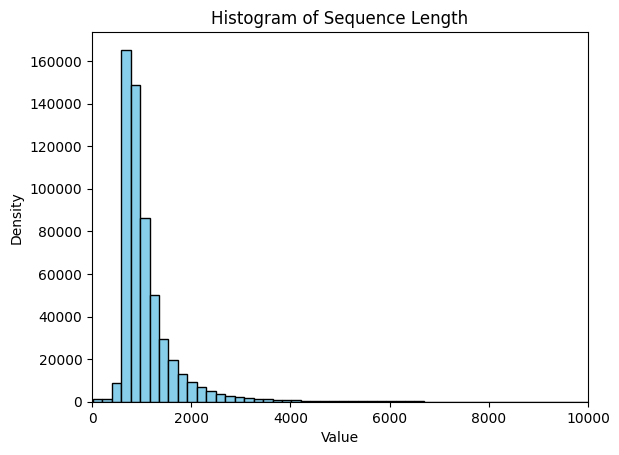

In [17]:

# 2. Create the histogram
# density=True normalizes the counts to form a probability density
plt.hist(df['seq_lenth'], bins=200, color='skyblue', edgecolor='black')
plt.xlim([0,10000])

# 3. Add titles and labels (optional)
plt.title('Histogram of Sequence Length')
plt.xlabel('Value')
plt.ylabel('Density')

# 4. Display the plot
plt.show()


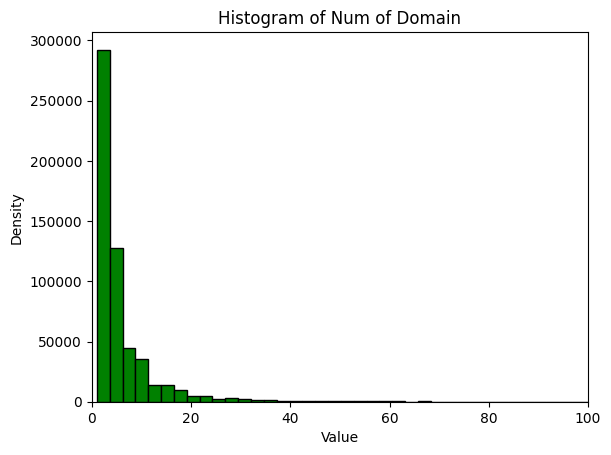

In [23]:


# 2. Create the histogram
# density=True normalizes the counts to form a probability density
plt.hist(df['num_of_domain'], bins=400, color='green', edgecolor='black')
plt.xlim([0,100])

# 3. Add titles and labels (optional)
plt.title('Histogram of Num of Domain')
plt.xlabel('Value')
plt.ylabel('Density')

# 4. Display the plot
plt.show()


In [29]:
df.groupby('num_of_domain').count()[:20]

,entry_id,sequence,Interpro_domain,seq_lenth
num_of_domain,,,,
1,116471,116471,116471,116471
2,99385,99385,99385,99385
3,76465,76465,76465,76465
4,54701,54701,54701,54701
5,40257,40257,40257,40257
6,32693,32693,32693,32693
7,26114,26114,26114,26114
8,18823,18823,18823,18823
9,15069,15069,15069,15069


In [30]:
df

,entry_id,sequence,Interpro_domain,seq_lenth,num_of_domain
0,A0A009HZR9,MNHHHEKKSINEALKDPVCGMAVTEESKFHEQVGIKTFYFCSEKCQ...,IPR007029:15-57|IPR011017:16-53|IPR044492:451-...,731,5
1,A0A009PG93,MVGKTDNQAPCQSSELWSQDKNWDITPELSTNERKALADYARCLAL...,IPR002104:416-616|IPR002104:444-607,735,2
2,A0A009R5Z4,KDAENDADADSDADADADSDVEPQALLGEDLPAALPAEAPQELVSD...,IPR041498:212-288|IPR049826:107-186|IPR049826:...,400,3
3,A0A009R6A6,VVAGPDGTWTVPNPGLNDGDEVTAVATDPAGNTSGPETAIVDAVGP...,IPR041498:156-231|IPR049826:51-130,232,2
4,A0A009S8P4,MDIETTGVKKYAFQDLVCISLLLNLHFTENVQFFVEPENSEDAKLI...,IPR049050:258-361,1283,1
...,...,...,...,...,...
564571,A0A7I4DQC5,MAILAPHNCNAIIGNFPSTKSSHAGPKSSTCVYGGVALYAREGIHL...,IPR000719:361-690|IPR004147:330-567,923,2
564572,A0A7I4DQL4,MHRGRSRNHSHCHDRSNRESLKKSLGVDEECGAQGTNKPWKLTWNL...,IPR001251:702-876|IPR001251:704-881|IPR001251:...,903,3
564573,A0A7I4DRB0,MAPHSHVPHLERRRVVGRWEELVSKAIDAKGKRPFLRLSRGEYEDT...,IPR003440:1049-1768|IPR026899:341-451|IPR02689...,1960,4
564574,A0A7I4DRJ8,MDGIATQAGALPRMTSMNKKIQGSLDDHRNENLRILSKLTAKRKAL...,IPR000368:272-560|IPR056735:13-126|IPR056736:1...,572,3


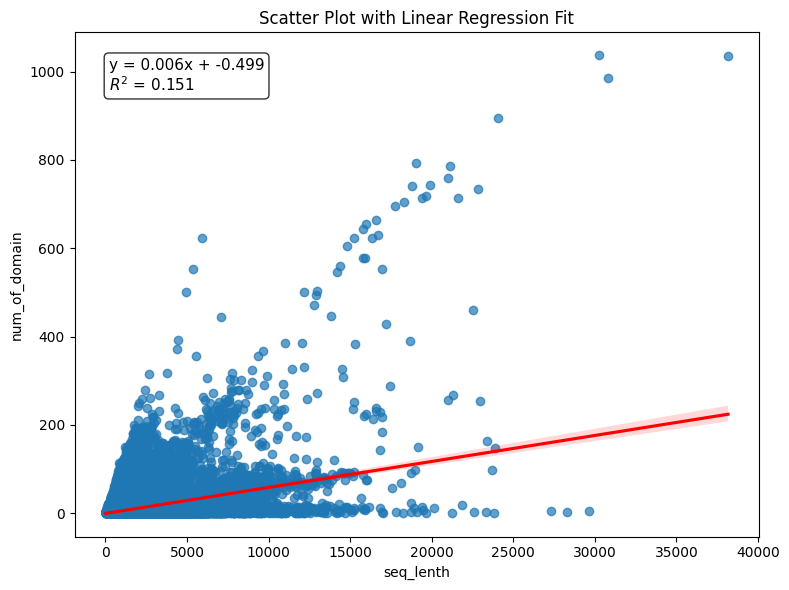

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Subset data
df_linear = df[['seq_lenth', 'num_of_domain']].dropna()

x = df_linear['seq_lenth'].values
y = df_linear['num_of_domain'].values

# 1. Fit linear regression: y = m x + b
m, b = np.polyfit(x, y, 1)

# 2. Predicted values and R^2
y_pred = m * x + b
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot

# 3. Plot
plt.figure(figsize=(8, 6))
sns.regplot(
    x=x,
    y=y,
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'}
)

# 4. Annotation text
eq_text = f'y = {m:.3f}x + {b:.3f}\n$R^2$ = {r2:.3f}'

plt.text(
    0.05, 0.95, eq_text,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.title('Scatter Plot with Linear Regression Fit')
plt.xlabel('seq_lenth')
plt.ylabel('num_of_domain')

plt.tight_layout()
plt.show()


In [33]:
df.describe()

,seq_lenth,num_of_domain
count,564576.000000,564576.000000
mean,1104.101060,6.001398
std,730.240048,11.078970
min,15.000000,1.000000
25%,746.000000,2.000000
50%,902.000000,3.000000
75%,1197.000000,7.000000
max,38162.000000,1037.000000
